# Ratios by signed electrode: is the gain different near the + and the − electrode of a pair? (4-fish, Kaden masks)

**Ratios.** As in `EOD_gain_ratios_top2_fish_pair_ls_4fish_kaden.ipynb`: the 1365-EOD clean emitter set, the 2 pairs with the
largest recorded |amplitude| of each EOD, $g = |V_\text{rec}| / |V_\text{pred}|$ for the emitter; my model (main phase,
unit current) and Denis' (peak-to-peak, his units), each on my mask midline.

**Signed electrode.** Each ratio belongs to one pair; it is put under the electrode of that pair (+ or −) that is nearer to the
emitter's mask midline (closest midline point, cm). So "10−" holds the pair-10 ratios of EODs where the fish was nearer pair 10's
− electrode. Each pair's 2 electrodes are side by side; missing boxes: no ratios.

The two models are in different units (V per model unit, V per Denis unit), so each panel has its own axis; what matters is
the + vs − difference within a pair.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set/gain_ratios_top2'
OUT = f'{BASE}/clean_emitter_set/ratio_by_signed_electrode'; os.makedirs(OUT, exist_ok=True)
PX_CM = P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
POLE_COL = {'+': '#33332F', '−': '#B5B5AF'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv').set_index('pair')
POLE = {p: (((e.x1, e.y1), (e.x2, e.y2)) if str(e.pol1).strip() == '+' else ((e.x2, e.y2), (e.x1, e.y1))) for p, e in EL.iterrows()}

R = {m: pd.read_csv(f'{SRC}/ratios_{m}_1365.csv') for m in ('mine', 'Denis')}
R = {m: d[d.kept].reset_index(drop=True) for m, d in R.items()}
for m, d in R.items():
    pole, dist = np.empty(len(d), object), np.zeros(len(d))
    for t in d.video.unique():
        z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); mids = z['mids']; idx = {int(k): i for i, k in enumerate(z['frames'])}
        for i in np.flatnonzero(d.video.to_numpy() == t):
            r = d.iloc[i]; (px, py), (mx, my) = POLE[int(r.pair)]
            xy = mids[idx[int(r.Frame)], LET.index(r.fish)] * (P - 1)                      # (101, row/col) px
            dp = np.hypot(xy[:, 1] - px, xy[:, 0] - py).min() / PX_CM; dm = np.hypot(xy[:, 1] - mx, xy[:, 0] - my).min() / PX_CM
            pole[i], dist[i] = ('+', dp) if dp < dm else ('−', dm)
    d['pole'], d['dist_cm'] = pole, dist; d['electrode'] = d.pair.astype(str) + d.pole
    d.to_csv(f'{OUT}/ratios_{m}_1365_by_signed_electrode.csv', index=False)
WHO = {'mine': 'my', 'Denis': "Denis'"}
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]

def table(d):
    g = d.groupby('electrode').agg(n=('gain', 'size'), median=('gain', 'median'), q25=('gain', lambda x: x.quantile(0.25)),
                                   q75=('gain', lambda x: x.quantile(0.75)), dist_cm=('dist_cm', 'median'))
    return g.reindex(ORDER)
for m in ('mine', 'Denis'):
    T = table(R[m][R[m].fish == 'B']); T.to_csv(f'{OUT}/fish_B_{m}_by_signed_electrode.csv')
    print(f'fish B, {m} model: ratios by signed electrode (median distance of the fish to that electrode in cm)')
    display(T.round(4 if m == 'Denis' else 3).dropna(how='all'))

fish B, mine model: ratios by signed electrode (median distance of the fish to that electrode in cm)


,n,median,q25,q75,dist_cm
electrode,,,,,
1−,77.0,0.301,0.271,0.331,2.433
2+,545.0,0.286,0.227,0.332,2.158
3+,3.0,0.478,0.414,0.570,4.426
3−,21.0,0.192,0.180,0.212,2.539
4−,3.0,0.381,0.355,0.662,4.672
6+,47.0,0.397,0.378,0.416,3.428
7+,12.0,0.542,0.524,0.590,4.567
7−,11.0,0.440,0.432,0.449,2.458
8+,30.0,0.448,0.363,0.503,2.209


fish B, Denis model: ratios by signed electrode (median distance of the fish to that electrode in cm)


,n,median,q25,q75,dist_cm
electrode,,,,,
1−,77.0,0.0037,0.0033,0.0042,2.4327
2+,543.0,0.0035,0.0030,0.0042,2.1584
3+,3.0,0.0051,0.0048,0.0055,4.4263
3−,23.0,0.0019,0.0018,0.0024,2.5945
4−,3.0,0.0061,0.0058,0.0068,4.6724
6+,47.0,0.0055,0.0053,0.0057,3.4278
7+,12.0,0.0054,0.0052,0.0056,4.5670
7−,11.0,0.0044,0.0042,0.0046,2.4580
8+,26.0,0.0049,0.0041,0.0053,2.2635


## Fish B

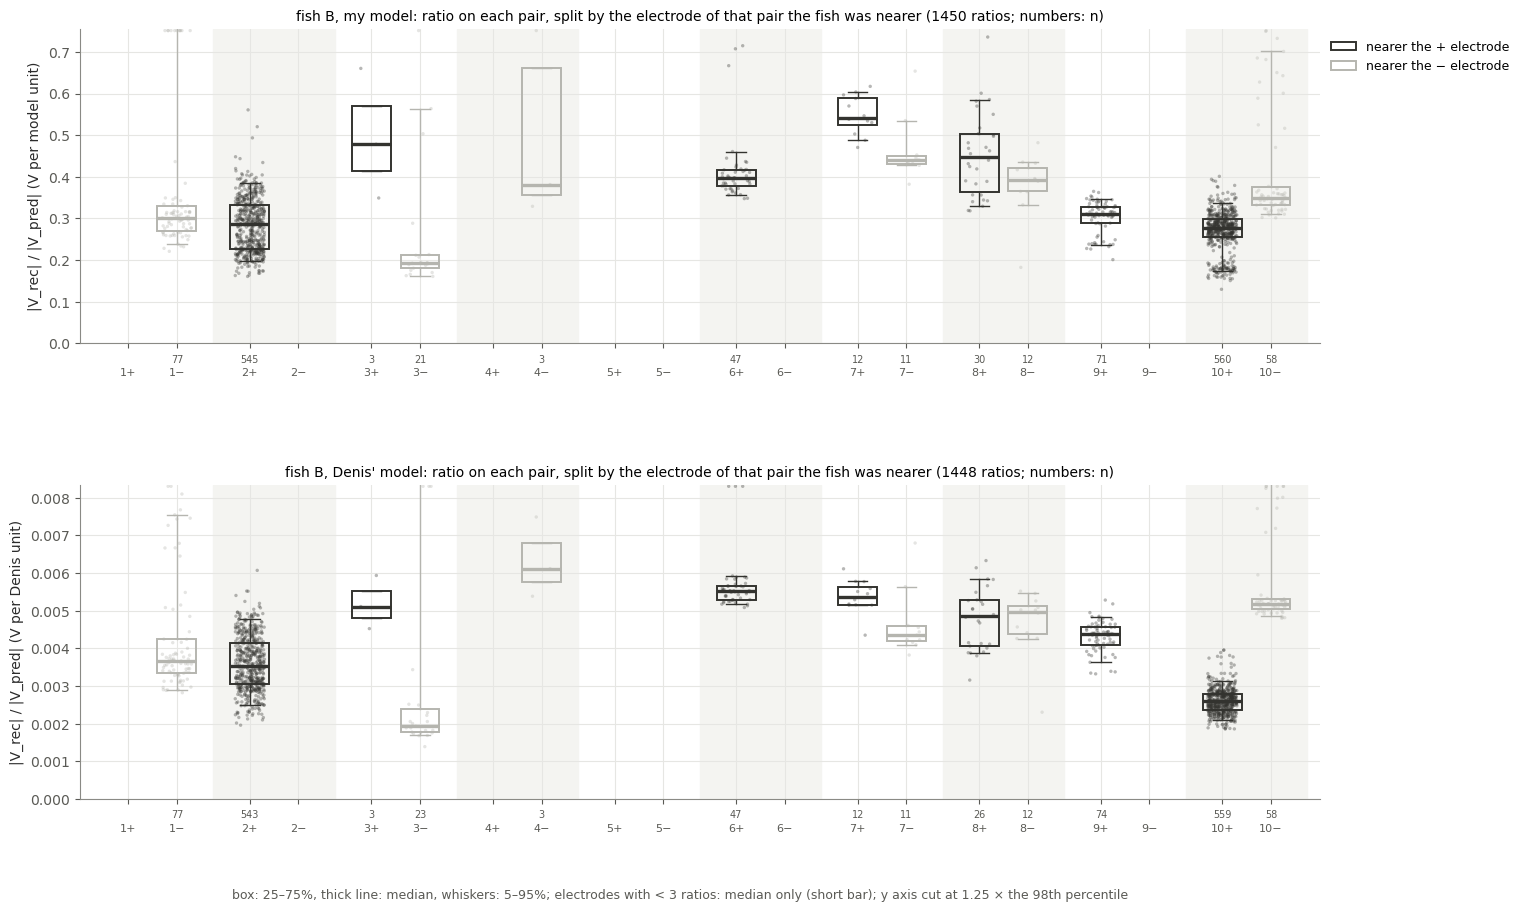

In [2]:
def box_by_electrode(ax, d, ylab, title):
    pos = {e: p + (-0.2 if e.endswith('+') else 0.2) for p, e in zip(np.repeat(np.arange(10), 2), ORDER)}
    jit = np.random.default_rng(0); top = np.percentile(d.gain, 98) * 1.25
    for e in ORDER:
        v = d[d.electrode == e].gain.to_numpy()
        if not len(v): continue
        c = POLE_COL[e[-1]]
        ax.scatter(pos[e] + jit.uniform(-0.12, 0.12, len(v)), np.minimum(v, top * 0.995), s=6, color=c, alpha=0.35, edgecolor='none', zorder=2)
        if len(v) >= 3:
            ax.boxplot([v], positions=[pos[e]], widths=0.32, whis=(5, 95), showfliers=False, patch_artist=True, zorder=3,
                       boxprops=dict(facecolor='none', edgecolor=c, lw=1.4), medianprops=dict(color=c, lw=2.4),
                       whiskerprops=dict(color=c), capprops=dict(color=c))
        else:
            ax.scatter([pos[e]], [np.median(v)], marker='_', s=200, color=c, lw=2.4, zorder=3)
        ax.text(pos[e], -0.035, f'{len(v)}', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=7, color='#5a5a55')
    for p in range(10):
        if p % 2: ax.axvspan(p - 0.5, p + 0.5, color='#f4f4f1', zorder=0)
    ax.set_xticks([pos[e] for e in ORDER]); ax.set_xticklabels(ORDER, fontsize=8)
    ax.tick_params(axis='x', pad=14)
    ax.set(xlim=(-0.6, 9.6), ylim=(0, top), ylabel=ylab); ax.set_title(title, fontsize=10)

fig, axs = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw=dict(hspace=0.45))
for ax, m in zip(axs, ('mine', 'Denis')):
    d = R[m][R[m].fish == 'B']
    box_by_electrode(ax, d, f'|V_rec| / |V_pred| ({"V per model unit" if m == "mine" else "V per Denis unit"})',
                     f'fish B, {WHO[m]} model: ratio on each pair, split by the electrode of that pair the fish was nearer '
                     f'({len(d)} ratios; numbers: n)')
axs[0].legend(handles=[Patch(facecolor='none', edgecolor=POLE_COL['+'], lw=1.4, label='nearer the + electrode'),
                       Patch(facecolor='none', edgecolor=POLE_COL['−'], lw=1.4, label='nearer the − electrode')],
              frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.text(0.5, 0.01, 'box: 25–75%, thick line: median, whiskers: 5–95%; electrodes with < 3 ratios: median only (short bar); y axis cut at 1.25 × the 98th percentile',
         ha='center', fontsize=9, color='#5a5a55')
fig.savefig(f'{OUT}/fish_B_ratio_by_signed_electrode.png', dpi=110, bbox_inches='tight'); plt.show()

## All four fish, for comparison

Median ratio per signed electrode and fish (dot size: n ratios; only electrodes with ≥ 3 ratios of that fish). If the + / −
difference of a pair is an electrode property, every fish should show it the same way.

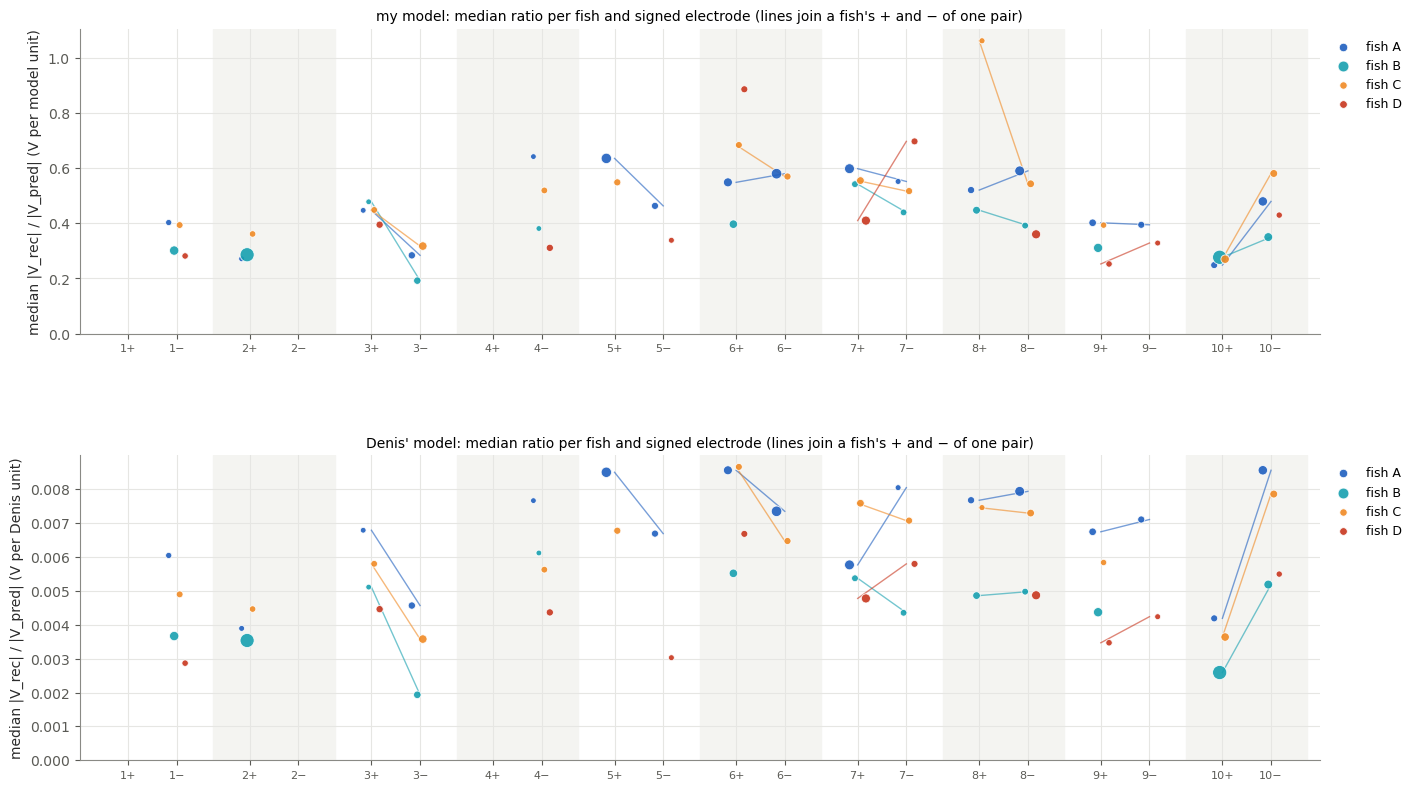

In [3]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9.5), gridspec_kw=dict(hspace=0.4))
xpos = {e: p + (-0.2 if e.endswith('+') else 0.2) for p, e in zip(np.repeat(np.arange(10), 2), ORDER)}
for ax, m in zip(axs, ('mine', 'Denis')):
    T = R[m].groupby(['fish', 'electrode']).gain.agg(['median', 'size']).reset_index()
    T = T[T['size'] >= 3]
    for j, f in enumerate(LET):
        t = T[T.fish == f]
        ax.scatter([xpos[e] + (j - 1.5) * 0.045 for e in t.electrode], t['median'], s=10 + 4 * np.sqrt(t['size']),
                   color=FISH_COL[f], edgecolor='white', lw=0.6, alpha=0.9, zorder=3, label=f'fish {f}')
        for p in range(1, 11):                                         # join a fish's + and − of the same pair
            a, b = t[t.electrode == f'{p}+'], t[t.electrode == f'{p}−']
            if len(a) and len(b): ax.plot([xpos[f'{p}+'], xpos[f'{p}−']], [a['median'].iloc[0], b['median'].iloc[0]], color=FISH_COL[f], lw=1, alpha=0.6, zorder=2)
    for p in range(10):
        if p % 2: ax.axvspan(p - 0.5, p + 0.5, color='#f4f4f1', zorder=0)
    ax.set_xticks([xpos[e] for e in ORDER]); ax.set_xticklabels(ORDER, fontsize=8)
    ax.set(xlim=(-0.6, 9.6), ylim=(0, None), ylabel=f'median |V_rec| / |V_pred| ({"V per model unit" if m == "mine" else "V per Denis unit"})')
    ax.set_title(f'{WHO[m]} model: median ratio per fish and signed electrode (lines join a fish\'s + and − of one pair)', fontsize=10)
    ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(f'{OUT}/all_fish_median_ratio_by_signed_electrode.png', dpi=110, bbox_inches='tight'); plt.show()